# Order–disorder: γ′ (L1₂) and β (B2) in Al–Ni

An ordered phase such as Ni₃Al (γ′, L1₂) or NiAl (β, B2) is an FCC or BCC
lattice whose sublattices are occupied unequally. A CALPHAD database describes
it as a *partitioned* phase over its disordered parent:

$$G = G_\mathrm{dis}(x) + \left[G_\mathrm{ord}(y) - G_\mathrm{ord}(x)\right],$$

where y are the site fractions of the ordered sublattices and x their site
average. With equal fractions on every sublattice the bracket vanishes, and the
phase is its parent exactly. So order appears as a second well in
site-fraction space. A grid over x alone cannot see it; pricing over y finds
it as a new composition set of the same phase.

Equivalent ordered variants (sublattices swapped) are duplicate minima.
Pricing adds symmetry-breaking constraints so the branch and bound searches
one variant, and duplicate detection compares sets modulo the permutation.

References for comparison:

- N. Dupin, I. Ansara and B. Sundman, *Thermodynamic re-assessment of the
  ternary system Al–Cr–Ni*, Calphad 25 (2001) 279–298: the database;
- A. J. Bradley and A. Taylor, *An X-ray analysis of the nickel–aluminium
  system*, Proc. R. Soc. Lond. A 159 (1937) 56–72: constitutional vacancies in
  Al-rich NiAl;
- H. Okamoto, *Al–Ni (aluminum–nickel)*, J. Phase Equilib. 14 (1993) 257–259:
  NiAl melts congruently at 1638 °C (1911 K).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from discopt.calphad import databases, equilibrium
from discopt.calphad.equilibrium.common import R_GAS
from discopt.calphad.models.partitioned import PartitionedPhase
from discopt.calphad.ops import NUM

db = databases.load("alni_dupin")
models = db.phase_models(("AL", "NI"))
phases = list(models.values())
for name, p in models.items():
    print(f"{name:9s} {type(p).__name__:17s} sites {p.site_ratios if hasattr(p, 'site_ratios') else ''}")

LIQUID    BinarySolution    sites 
AL3NI1    StoichiometricPhase sites 
AL3NI2    CEFPhase          sites (3.0, 2.0, 1.0)
AL3NI5    StoichiometricPhase sites 
BCC_A2    CEFPhase          sites (1.0, 3.0)
BCC_B2    PartitionedPhase  sites (0.5, 0.5, 3.0)
FCC_A1    CEFPhase          sites (1.0, 1.0)
FCC_L12   PartitionedPhase  sites (0.75, 0.25, 1.0)


## The ordered phase contains its parent

FCC_L12 is (Al,Ni)₀.₇₅(Al,Ni)₀.₂₅ over FCC_A1. With equal site fractions,
G(FCC_L12) is G(FCC_A1) at the same composition:

In [2]:
l12 = models["FCC_L12"]
for x_al in (0.1, 0.25, 0.4):
    T = 1200.0
    u = l12.variables_from_site_fractions([{"AL": x_al, "NI": 1 - x_al}] * 2 + [{"VA": 1.0}])
    ud = l12.disordered.variables_from_site_fractions([{"AL": x_al, "NI": 1 - x_al}, {"VA": 1.0}])
    g_ord = float(l12.gibbs(u, NUM, T)) * R_GAS * T
    g_dis = float(l12.disordered.gibbs(ud, NUM, T)) * R_GAS * T
    print(f"x(Al) = {x_al}: G(L12, disordered y) = {g_ord:.6f}  G(A1) = {g_dis:.6f} J/mol")

x(Al) = 0.1: G(L12, disordered y) = -74626.037107  G(A1) = -74626.037107 J/mol
x(Al) = 0.25: G(L12, disordered y) = -91705.002199  G(A1) = -91705.002199 J/mol
x(Al) = 0.4: G(L12, disordered y) = -99515.365480  G(A1) = -99515.365480 J/mol


## γ + γ′ at 1200 K, certified

At x(Al) = 0.22 the equilibrium is disordered γ (FCC_A1) and ordered γ′.
Pricing finds the ordered well of FCC_L12. The global certificate covers every
phase, including BCC_B2 with its vacancies.

In [3]:
res = equilibrium(phases, x=0.22, T=1200.0, certify="none")
cert = res.certify()
for cs in res.composition_sets:
    order = cs.phase.degree_of_order(cs.y) if isinstance(cs.phase, PartitionedPhase) else 0.0
    print(f"{cs.phase.name:8s} x(Al) = {float(cs.x[0]):.4f}  degree of order max|y_s − x| = {order:.3f}")
print("certificate:", cert.level.name)

FCC_A1   x(Al) = 0.1470  degree of order max|y_s − x| = 0.000
FCC_L12  x(Al) = 0.2301  degree of order max|y_s − x| = 0.677
certificate: CERTIFIED_TO_TOLERANCE


In [4]:
from pycalphad import Database  # noqa: E402
from pycalphad import equilibrium as peq  # noqa: E402
from pycalphad import variables as v  # noqa: E402

pdb = Database(str(databases.fetch("alni_dupin")))
eq = peq(pdb, ["AL", "NI", "VA"], sorted(models), {v.X("AL"): 0.22, v.T: 1200.0, v.P: 101325, v.N: 1})
print(
    "pycalphad:",
    [(str(n), round(float(c[0]), 4)) for n, c in zip(np.squeeze(eq.Phase.values), np.squeeze(eq.X.values)) if n],
)

pycalphad: [('FCC_L12', 0.2302), ('FCC_L12', 0.147)]


Both codes find the same two sets. (pycalphad names the disordered set by the
phase it was found in; here a set's degree of order decides whether it is γ or
γ′.)

## Constitutional vacancies in β

Dupin's B2 is (Al,Ni,Va)₀.₅(Al,Ni,Va)₀.₅. On the Al-rich side of NiAl, β takes
up the excess Al by leaving Ni sites empty instead of putting Al on them, as
Bradley and Taylor found by X-ray density measurements. Across β's
single-phase range at 1200 K:

x(Al) = 0.380: vacancy site fraction 1.83e-04
x(Al) = 0.400: vacancy site fraction 2.26e-04
x(Al) = 0.420: vacancy site fraction 2.86e-04
x(Al) = 0.440: vacancy site fraction 3.77e-04
x(Al) = 0.460: vacancy site fraction 5.30e-04
x(Al) = 0.480: vacancy site fraction 8.56e-04
x(Al) = 0.500: vacancy site fraction 3.33e-03
x(Al) = 0.520: vacancy site fraction 3.72e-02
x(Al) = 0.540: vacancy site fraction 7.18e-02


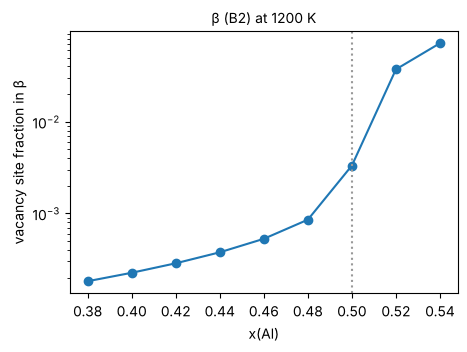

In [5]:
beta = models["BCC_B2"]
xv, vac = [], []
for x in np.linspace(0.38, 0.56, 10):
    r = equilibrium(phases, x=float(x), T=1200.0, certify="none")
    total = sum(c.amount for c in r.composition_sets)
    for cs in r.composition_sets:
        if cs.phase is beta and cs.amount > 0.99 * total:
            sf = beta.site_fractions(cs.y)
            xv.append(float(cs.x[0]))
            vac.append(0.5 * (sf[0]["VA"] + sf[1]["VA"]))
for x, va in zip(xv, vac):
    print(f"x(Al) = {x:.3f}: vacancy site fraction {va:.2e}")
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.semilogy(xv, vac, "o-")
ax.axvline(0.5, color="0.6", ls=":")
ax.set_xlabel("x(Al)")
ax.set_ylabel("vacancy site fraction in β")
ax.set_title("β (B2) at 1200 K", fontsize=10)
plt.show()

The vacancy fraction rises by orders of magnitude past the stoichiometric
composition, the signature of constitutional vacancies.

A phase that can hold a vacancy on *every* sublattice has no global minimum as
written: a dilute fraction of atoms in an empty lattice gains unbounded
entropy per atom. Such a phase is modeled over formula units at least half
occupied (`min_occupancy = 0.5`), far beyond the few percent seen here, and its
certificate says so:

In [6]:
print([m for m in cert.messages if "occupancy" in m])

['BCC_A2, BCC_B2: vacancies on every sublattice; bounds cover formula units at least 0.5 occupied (min_occupancy)']


## Congruent melting of NiAl

The temperature where liquid first appears at x(Al) = 0.5, by bisection:

In [7]:
def has_liquid(T):
    r = equilibrium(phases, x=0.5, T=T, certify="none")
    return any(cs.phase.name == "LIQUID" and cs.amount > 1e-9 for cs in r.composition_sets)


lo, hi = 1800.0, 2000.0
while hi - lo > 0.05:
    mid = 0.5 * (lo + hi)
    lo, hi = (lo, mid) if has_liquid(mid) else (mid, hi)
t_melt = 0.5 * (lo + hi)
print(f"NiAl melts at {t_melt:.1f} K with this database; Okamoto (1993) gives 1911 K (1638 °C)")
for T in (t_melt - 2.0, t_melt + 2.0):
    eq = peq(pdb, ["AL", "NI", "VA"], sorted(models), {v.X("AL"): 0.5, v.T: T, v.P: 101325, v.N: 1})
    print(f"  pycalphad at {T:.1f} K:", [str(n) for n in np.squeeze(eq.Phase.values) if n])

NiAl melts at 1951.3 K with this database; Okamoto (1993) gives 1911 K (1638 °C)


  pycalphad at 1949.3 K: ['BCC_B2']
  pycalphad at 1953.3 K: ['LIQUID']


pycalphad puts the melting point at the same temperature on this database, so
the 40 K difference from the experimental value belongs to the database file,
not to the solver.

## What is open

With β itself active and nearly perfectly ordered (β + γ′ at x(Al) = 0.3, or
β + Al₃Ni₂ at 0.58, 1200 K), the minimizer of β's Ψ sits on a corner of the
site-fraction box, and the global bound stops short of −ε: those equilibria end
`GLOBAL_SEARCH_INCOMPLETE` (bounds −1.4e-4 and −0.22 against ε = 1e-5). The
solutions themselves agree with pycalphad; only the proof is incomplete. See
`docs/architecture.md` §9.22.